In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from hyperparameter_search import HYPERPARAMETER_GROUPS
from utils import AUX_HEAD_KEYS
from tqdm import tqdm
import math

In [40]:
def increase_brightness(color: str | tuple[float, float, float], factor: float):
    if isinstance(color, str):
        r = int(color[1:3], 16)
        g = int(color[3:5], 16)
        b = int(color[5:7], 16)
    else:
        # seaborn/matplotlib tuples are floats in 0-1
        r, g, b = (int(round(c * 255)) for c in color)

    factor = min(max(factor, 0.0), 1.0)
    r = int(r + (255 - r) * factor)
    g = int(g + (255 - g) * factor)
    b = int(b + (255 - b) * factor)
    return f"#{r:02x}{g:02x}{b:02x}"

In [101]:
data = pd.read_csv("results/aux_head_regression_scores.csv")
data["run_number"] = data["model_name"].str[-1].astype(int)
data["model_name"] = data["model_name"].str[:-3]
data["aux_weight"] = data["model_name"].str.extract(r"_w([\d\.]+)$").astype(float)
data["model_name"] = data["model_name"].str.replace(r"_w[\d\.]+$", "", regex=True)
data["readable_name"] = data["model_name"] + data["aux_weight"].map(lambda x: f" Weight={x}" if x > 0 else "")
data

,model_name,target,iteration,r2_score,mae,target_stddev,run_number,aux_weight,readable_name
0,curvature_far,velocity_forward,0,0.914662,0.242653,1.408289,1,0.1,curvature_far Weight=0.1
1,curvature_far,velocity_lateral,0,0.832726,0.017034,0.086152,1,0.1,curvature_far Weight=0.1
2,curvature_far,track_curvature_0_50,0,0.319172,0.274817,0.512203,1,0.1,curvature_far Weight=0.1
3,curvature_far,track_curvature_1_00,0,0.337755,0.294877,0.560904,1,0.1,curvature_far Weight=0.1
4,curvature_far,track_curvature_1_50,0,0.260252,0.318591,0.575512,1,0.1,curvature_far Weight=0.1
...,...,...,...,...,...,...,...,...,...
32125,velocity_forward,wheel_slip_forward_front_right,600,0.663667,0.071581,0.273760,0,1.0,velocity_forward Weight=1.0
32126,velocity_forward,wheel_slip_lateral_front_right,600,0.782832,0.004845,0.016560,0,1.0,velocity_forward Weight=1.0
32127,velocity_forward,wheel_slip_forward_back_right,600,0.656847,0.072000,0.274186,0,1.0,velocity_forward Weight=1.0
32128,velocity_forward,wheel_slip_lateral_back_right,600,0.411862,0.002022,0.004823,0,1.0,velocity_forward Weight=1.0


{'curvature_close Weight=1.0': '#1f77b4', 'curvature_close Weight=0.3': '#78add2', 'curvature_close Weight=0.1': '#d2e3f0', 'all Weight=1.0': '#ff7f0e', 'all Weight=0.3': '#ffb26e', 'all Weight=0.1': '#ffe5ce', 'baseline': '#2ca02c'}


100%|██████████| 27/27 [00:13<00:00,  2.07it/s]


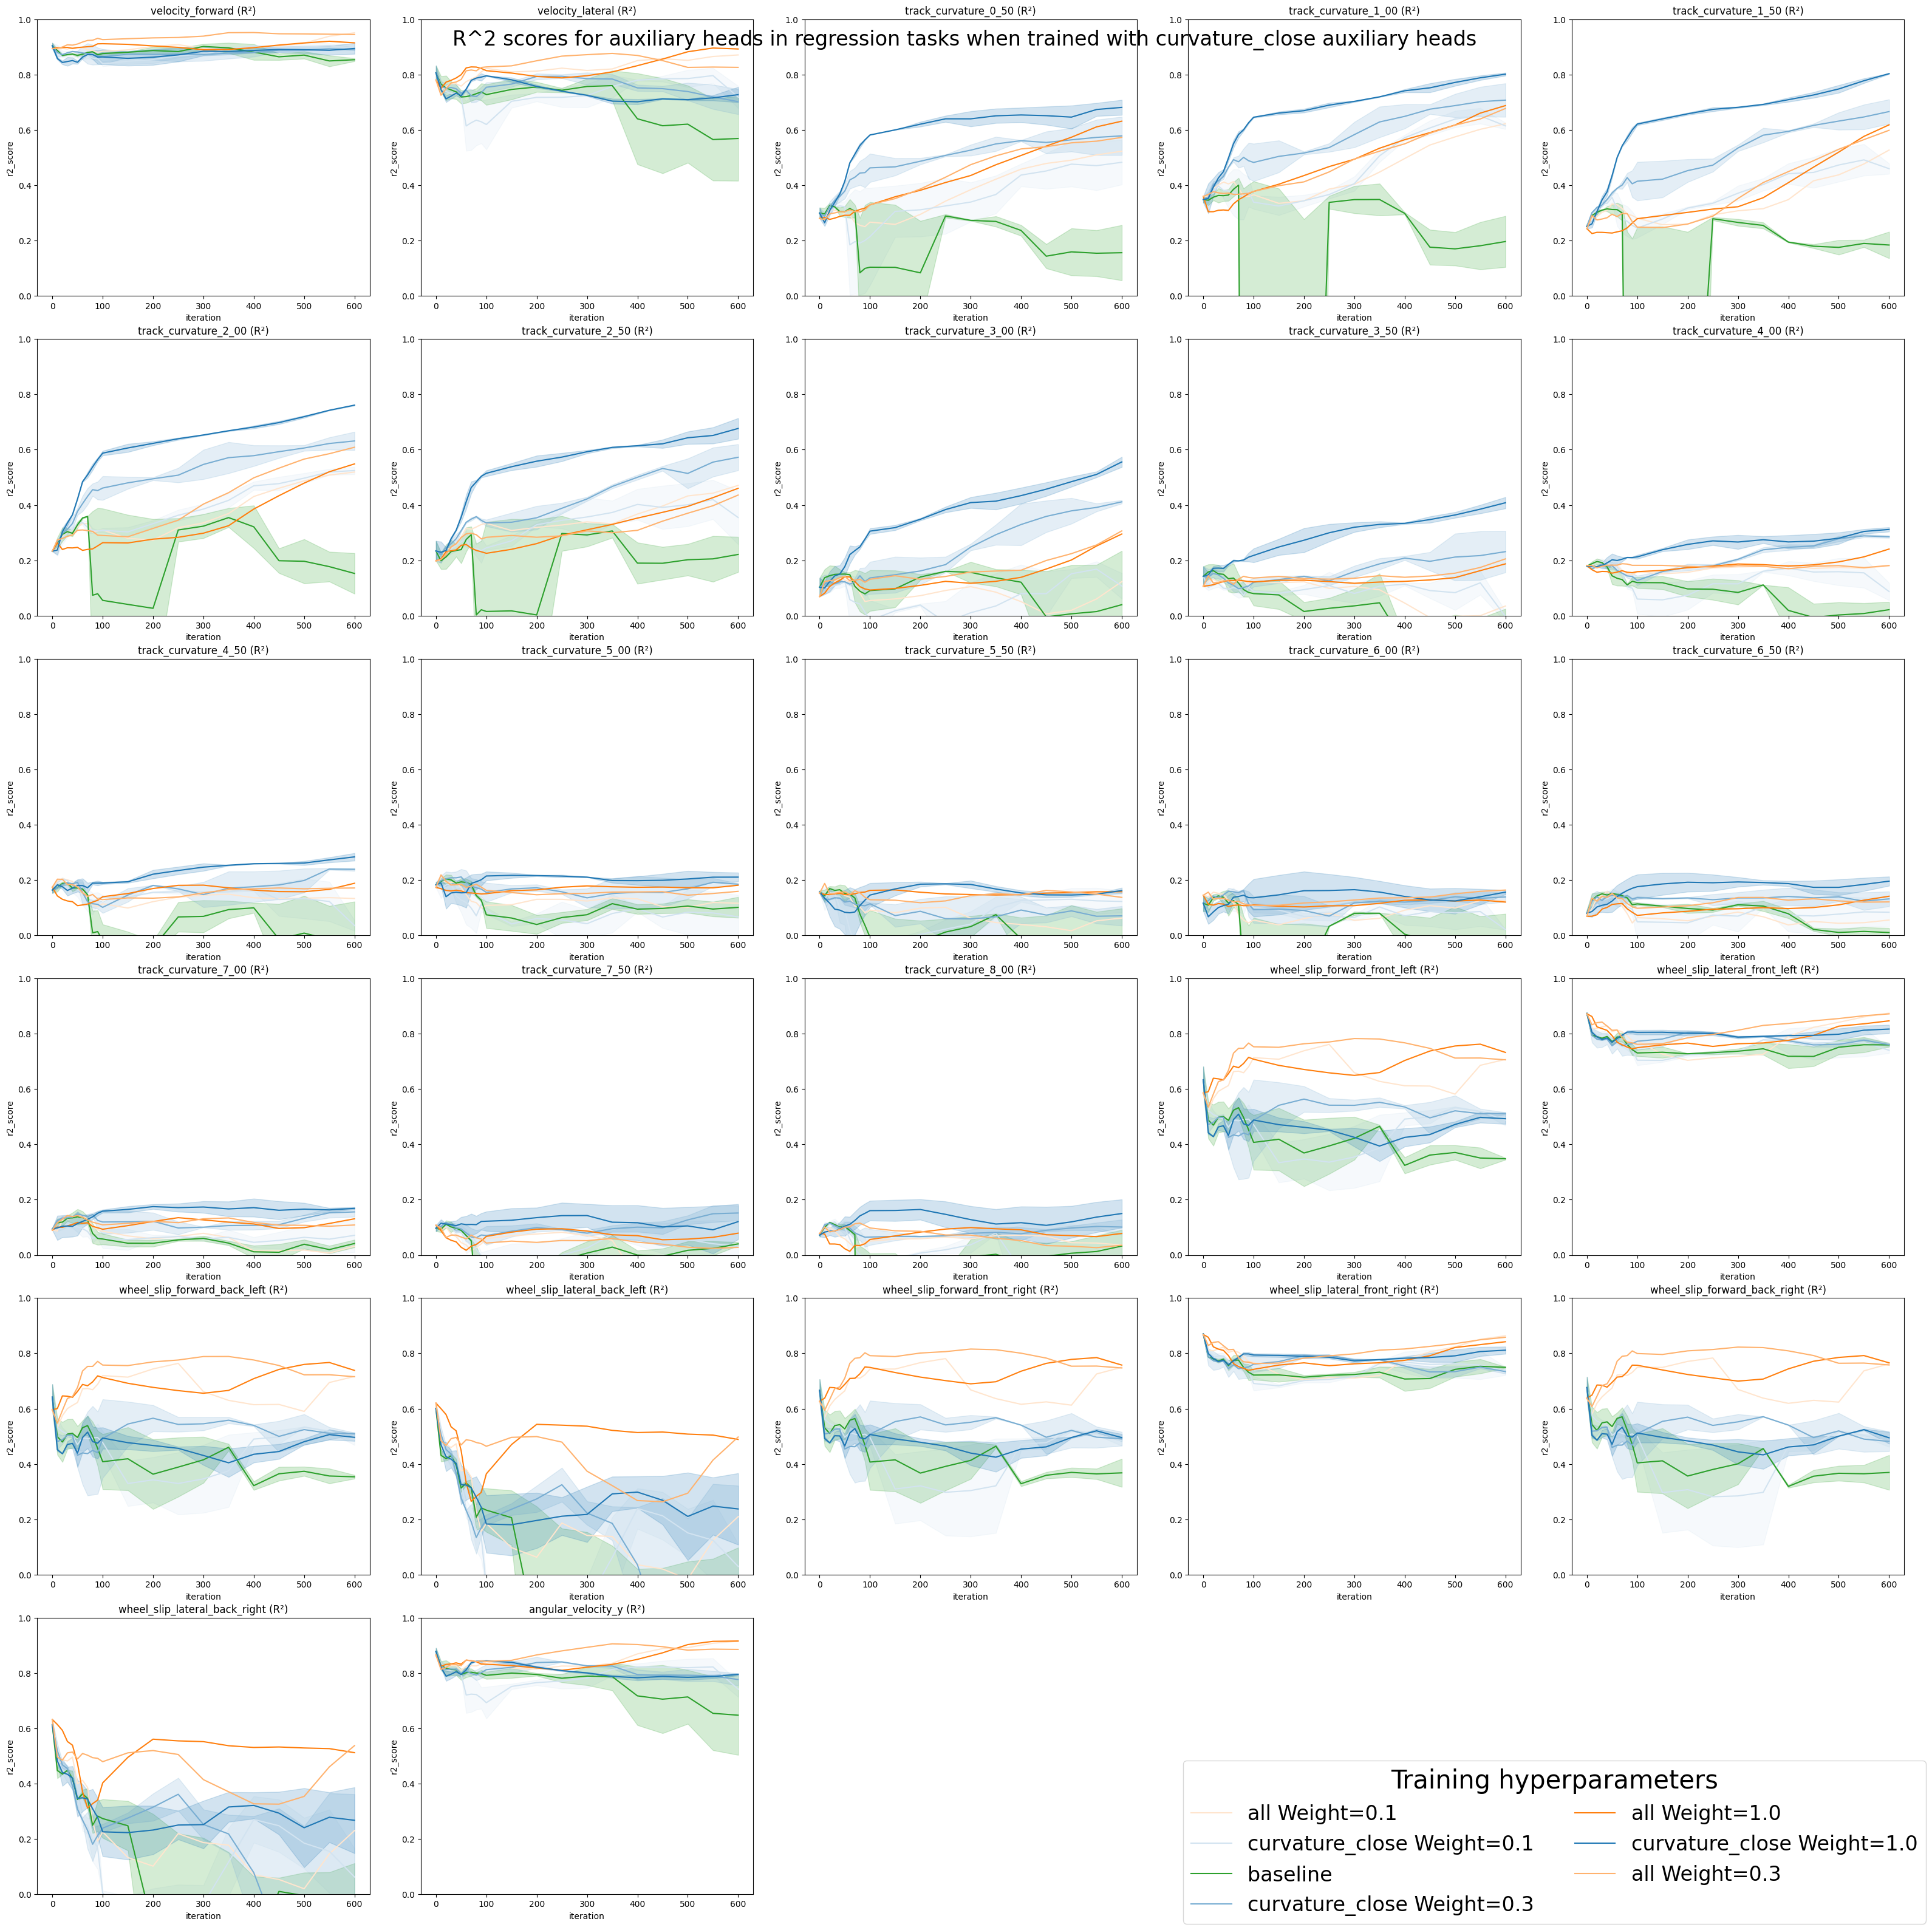

In [110]:
ANALYSE_GROUP = "curvature_close"
ANALYSE_GROUPS = ("curvature_close", "all", "baseline")
KEYS_TO_ANALYSE = ["velocity_forward", "curvature"]
to_show = data[data["model_name"].isin(ANALYSE_GROUPS)]

ROWS = math.ceil(math.sqrt(len(AUX_HEAD_KEYS)))
COLS = math.ceil(len(AUX_HEAD_KEYS) / ROWS)
fig, axs = plt.subplots(ROWS, COLS, figsize=(32, 32))
fig.tight_layout(pad=3)

major_palette = sns.color_palette("tab10", n_colors=len(ANALYSE_GROUPS))


palette = {
    f"{group} Weight={weight}" if weight > 0 else group: 
        increase_brightness(major_palette[j], 0.4*i) 
        for j, group in enumerate(ANALYSE_GROUPS) 
        for i, weight in enumerate(sorted(to_show[to_show["model_name"] == group]["aux_weight"].unique(), reverse=True))
}

for idx, key in tqdm(enumerate(AUX_HEAD_KEYS), total=len(AUX_HEAD_KEYS)):
    row_idx = idx // COLS
    col_idx = idx % COLS

    this_key = to_show[to_show["target"] == key].sort_values("iteration")
    this_key["r2_score"] = this_key["r2_score"].groupby([this_key["readable_name"], this_key["run_number"]]).transform(lambda x: x.rolling(5, min_periods=1).mean())
    
    sns.lineplot(
        data=this_key,
        x="iteration",
        y="r2_score",
        hue=this_key["readable_name"],
        ax=axs[row_idx, col_idx],
        palette=palette,
        legend=(idx ==0),
    ).set(ylim=(0, 1),
          title=f"{key} (R²)",)


handles, labels = [], []
for ax in fig.axes:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

by_label = dict(zip(labels, handles))

fig.legend(by_label.values(), by_label.keys(), loc="lower right",
    bbox_to_anchor=(1.0, 0.0), 
    ncol=2, 
    title="Training hyperparameters",
    fontsize=24, title_fontsize=30, markerscale=2.5)

leg = axs[0, 0].get_legend()
if leg is not None:
    leg.remove()


fig.suptitle(f"R^2 scores for auxiliary heads in regression tasks when trained with {ANALYSE_GROUP} auxiliary heads", fontsize=24)

# Remove the leftover plots
for i in range(len(AUX_HEAD_KEYS), ROWS * COLS):
    row_idx = i // COLS
    col_idx = i % COLS
    fig.delaxes(axs[row_idx, col_idx])